<a href="https://colab.research.google.com/github/triprasetyaningsih7700-max/index-html/blob/main/uts_pmB_202431049_Tri.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler

Membuat Dataset

In [3]:
data = {
    "Instansi": [f"Instansi {chr(65+i)}" for i in range(15)],
    "Nilai_IPP": [
        72, 75, 78, 80, 74, 82, 77, 79,
        81, 76, 73, 85, 78, np.nan, 150
    ],
    "Tahun": [2025] * 15
}

df = pd.DataFrame(data)

print("Dataset awal:")
print(df)

Dataset awal:
      Instansi  Nilai_IPP  Tahun
0   Instansi A       72.0   2025
1   Instansi B       75.0   2025
2   Instansi C       78.0   2025
3   Instansi D       80.0   2025
4   Instansi E       74.0   2025
5   Instansi F       82.0   2025
6   Instansi G       77.0   2025
7   Instansi H       79.0   2025
8   Instansi I       81.0   2025
9   Instansi J       76.0   2025
10  Instansi K       73.0   2025
11  Instansi L       85.0   2025
12  Instansi M       78.0   2025
13  Instansi N        NaN   2025
14  Instansi O      150.0   2025


Memeriksa Missing Value

In [4]:
print("\nMissing value:")
print(df.isnull().sum())


Missing value:
Instansi     0
Nilai_IPP    1
Tahun        0
dtype: int64


Mengisi Missing Value dengan Median

In [5]:
imputer = SimpleImputer(strategy="median")
df[["Nilai_IPP"]] = imputer.fit_transform(
    df[["Nilai_IPP"]]
)

print("\nData setelah missing value ditangani:")
print(df)


Data setelah missing value ditangani:
      Instansi  Nilai_IPP  Tahun
0   Instansi A       72.0   2025
1   Instansi B       75.0   2025
2   Instansi C       78.0   2025
3   Instansi D       80.0   2025
4   Instansi E       74.0   2025
5   Instansi F       82.0   2025
6   Instansi G       77.0   2025
7   Instansi H       79.0   2025
8   Instansi I       81.0   2025
9   Instansi J       76.0   2025
10  Instansi K       73.0   2025
11  Instansi L       85.0   2025
12  Instansi M       78.0   2025
13  Instansi N       78.0   2025
14  Instansi O      150.0   2025


Medeteksi Outlier denfan menggunakan IQR

In [6]:
Q1 = df["Nilai_IPP"].quantile(0.25)
Q3 = df["Nilai_IPP"].quantile(0.75)
IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier = df[
    (df["Nilai_IPP"] < batas_bawah) |
    (df["Nilai_IPP"] > batas_atas)
]

print("\nBatas bawah:", batas_bawah)
print("Batas atas:", batas_atas)
print("Kandidat outlier:")
print(outlier)


Batas bawah: 68.0
Batas atas: 88.0
Kandidat outlier:
      Instansi  Nilai_IPP  Tahun
14  Instansi O      150.0   2025


Validasi Boxplot

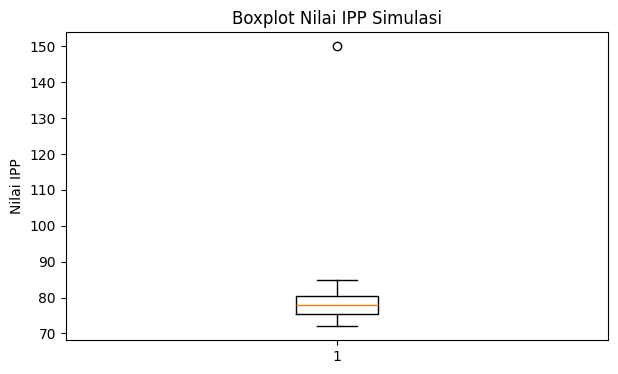

In [7]:
plt.figure(figsize=(7, 4))
plt.boxplot(df["Nilai_IPP"])
plt.title("Boxplot Nilai IPP Simulasi")
plt.ylabel("Nilai IPP")
plt.show()

Menyimpan data yang sudah dibersihkan

In [8]:
df_model = df[df["Nilai_IPP"] <= batas_atas].copy()

In [9]:
def kategori(nilai):
    if nilai < 75:
        return "Rendah"
    elif nilai <= 80:
        return "Sedang"
    else:
        return "Tinggi"

df_model["Kategori"] = df_model["Nilai_IPP"].apply(kategori)

print("\nDataset untuk model:")
print(df_model[["Instansi", "Nilai_IPP", "Kategori"]])


Dataset untuk model:
      Instansi  Nilai_IPP Kategori
0   Instansi A       72.0   Rendah
1   Instansi B       75.0   Sedang
2   Instansi C       78.0   Sedang
3   Instansi D       80.0   Sedang
4   Instansi E       74.0   Rendah
5   Instansi F       82.0   Tinggi
6   Instansi G       77.0   Sedang
7   Instansi H       79.0   Sedang
8   Instansi I       81.0   Tinggi
9   Instansi J       76.0   Sedang
10  Instansi K       73.0   Rendah
11  Instansi L       85.0   Tinggi
12  Instansi M       78.0   Sedang
13  Instansi N       78.0   Sedang


In [10]:
X = df_model[["Nilai_IPP"]]
y = df_model["Kategori"]

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42,
    stratify=y
)

In [12]:
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [13]:
y_pred = knn.predict(X_test)

print("\nNilai aktual:")
print(y_test.to_list())

print("\nHasil prediksi:")
print(y_pred.tolist())

print("\nAkurasi model:")
print(accuracy_score(y_test, y_pred))

print("\nLaporan klasifikasi:")
print(classification_report(y_test, y_pred, zero_division=0))


Nilai aktual:
['Tinggi', 'Sedang', 'Rendah', 'Sedang']

Hasil prediksi:
['Tinggi', 'Sedang', 'Rendah', 'Sedang']

Akurasi model:
1.0

Laporan klasifikasi:
              precision    recall  f1-score   support

      Rendah       1.00      1.00      1.00         1
      Sedang       1.00      1.00      1.00         2
      Tinggi       1.00      1.00      1.00         1

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



In [14]:
data_baru = pd.DataFrame({"Nilai_IPP": [79]})
hasil = knn.predict(data_baru)

print("\nPrediksi kategori nilai IPP 79:", hasil[0])


Prediksi kategori nilai IPP 79: Sedang
